In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Loading  Excel dataset (records)
df = pd.read_excel("Raisin_Dataset.xlsx")
print("Shape (rows, columns):", df.shape)
print("\nColumn names and types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nTarget class counts:")
print(df["Class"].value_counts())

Shape (rows, columns): (900, 8)

Column names and types:
Area                 int64
MajorAxisLength    float64
MinorAxisLength    float64
Eccentricity       float64
ConvexArea           int64
Extent             float64
Perimeter          float64
Class               object
dtype: object

First 5 rows:


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen



Missing values per column:
Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0
dtype: int64

Target class counts:
Class
Kecimen    450
Besni      450
Name: count, dtype: int64


In [ ]:
# Separate both the features and target
X = df.drop(columns=["Class"])
y = df["Class"]
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# Scale features for KNN (feature scales differ widely)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 720
Testing samples: 180


In [ ]:
dt_model = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print(" Decision Tree Results ")
print("Test Accuracy:", round(accuracy_score(y_test, dt_pred), 4))
print("\nClassification_Report:")
print(classification_report(y_test, dt_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

 Decision Tree Results 
Test Accuracy: 0.85

Classification_Report:
              precision    recall  f1-score   support

       Besni       0.91      0.78      0.84        90
     Kecimen       0.81      0.92      0.86        90

    accuracy                           0.85       180
   macro avg       0.86      0.85      0.85       180
weighted avg       0.86      0.85      0.85       180

Confusion Matrix:
[[70 20]
 [ 7 83]]


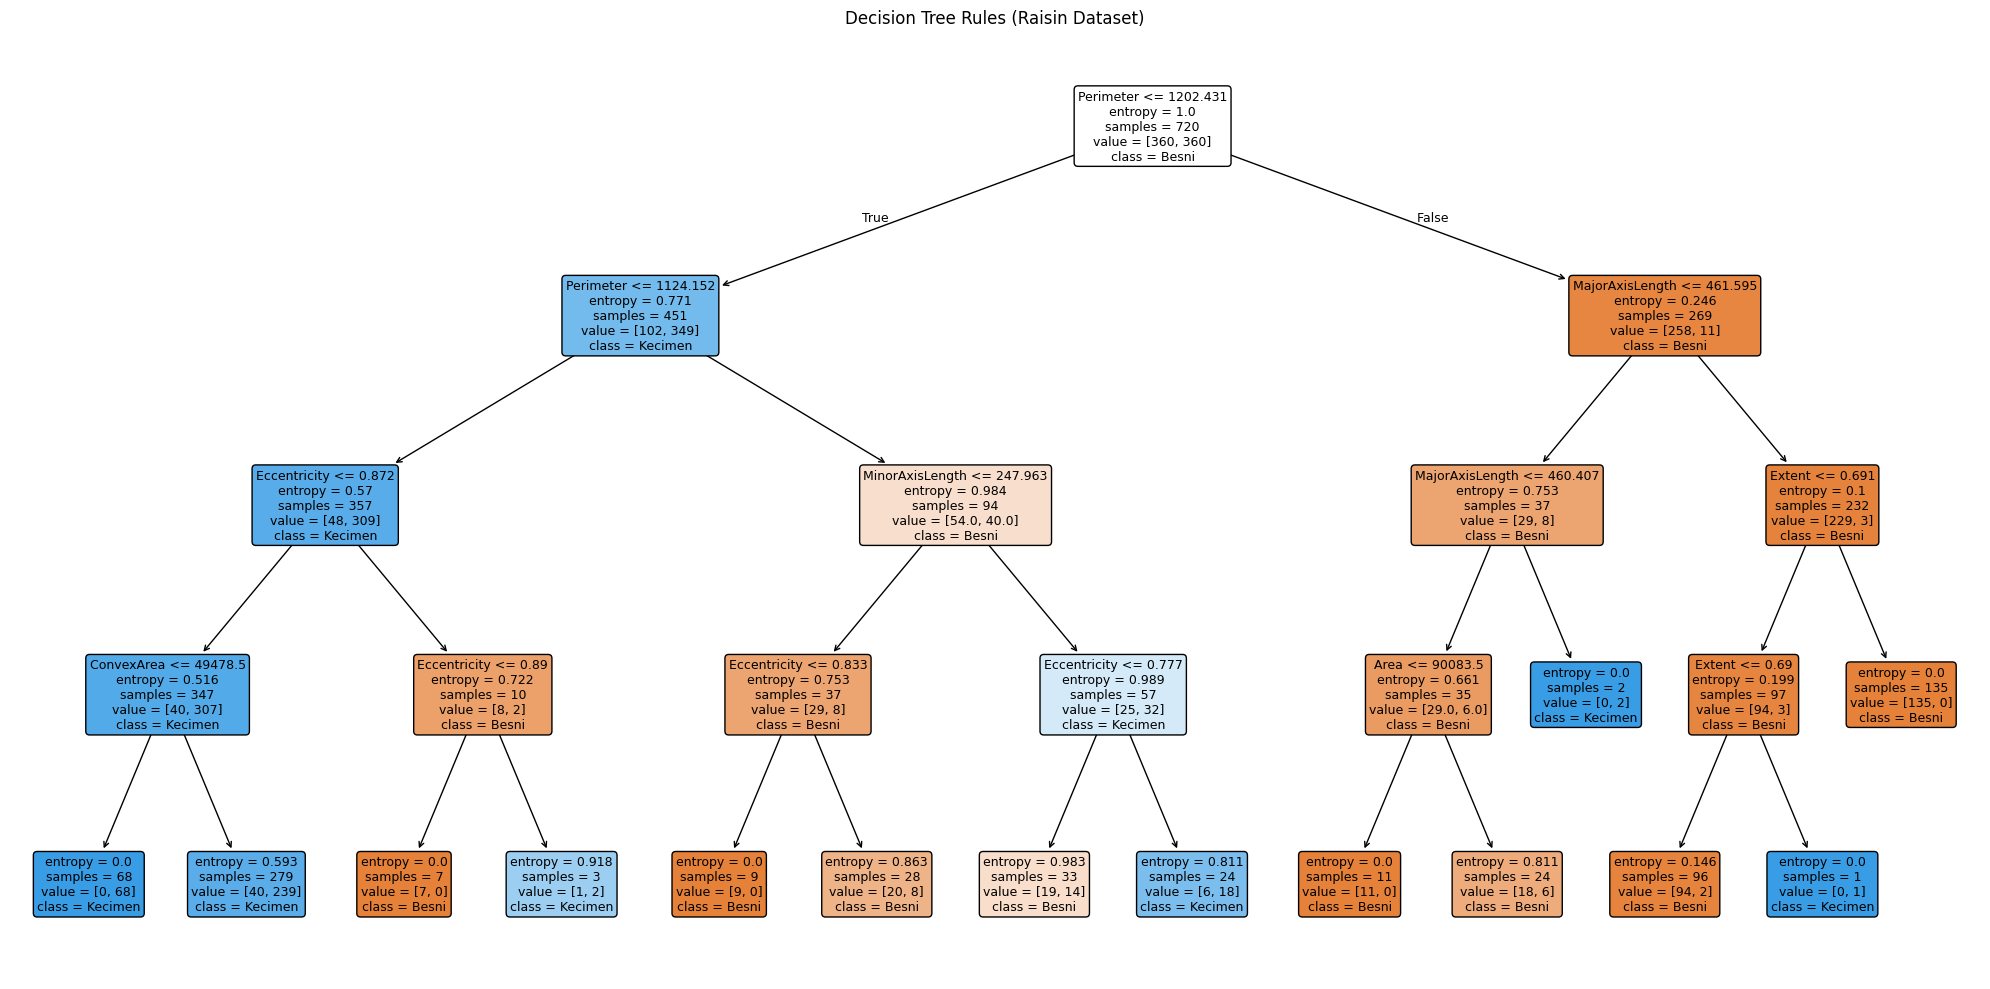

In [ ]:
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Rules (Raisin Dataset)")
plt.tight_layout()
plt.show()

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

print(" KNN (k=5) Results")
print("Test Accuracy:", round(accuracy_score(y_test, knn_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, knn_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, knn_pred))

 KNN (k=5) Results
Test Accuracy: 0.8611

Classification Report:
              precision    recall  f1-score   support

       Besni       0.93      0.78      0.85        90
     Kecimen       0.81      0.94      0.87        90

    accuracy                           0.86       180
   macro avg       0.87      0.86      0.86       180
weighted avg       0.87      0.86      0.86       180

Confusion Matrix:
[[70 20]
 [ 5 85]]


Decision Tree Accuracy : 0.8500
KNN (k=5) Accuracy     : 0.8611


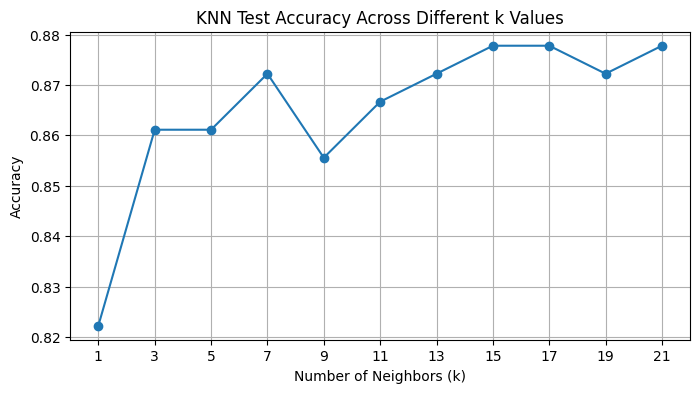

In [ ]:
print(f"Decision Tree Accuracy : {accuracy_score(y_test, dt_pred):.4f}")
print(f"KNN (k=5) Accuracy     : {accuracy_score(y_test, knn_pred):.4f}")

k_values = range(1, 22, 2)
k_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    k_scores.append(accuracy_score(y_test, preds))

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), k_scores, marker="o")
plt.title("KNN Test Accuracy Across Different k Values")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()